### 1. Introduction

Notebook 1: Exploratory Data Analysis  
Question: What drives the prices of art supplies in Sri Lanka?  
Data: collected from 3 online shops (haanz.lk, shanscraftsstore.com, jencilstore.com), 2181 raw and processed 1352 art-only products (data_processing/ and cleaning_report.txt)

### 2. Load the dataset

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/art_supplies_clean.csv")

In [2]:
df.shape

(1352, 21)

In [3]:
df.head()

,site,product_id,name,url,category_group,brand,brand_grouped,grade,paper_size,volume_ml,...,paper_gsm,pack_count,is_set,n_variants,is_variable,on_sale,in_stock,name_word_count,price_lkr,log_price
0,haanz.lk,66205,Tombow Fudenosuke Brush Pen -Soft Tip,https://www.haanz.lk/product/tombow-fudenosuke...,Pens & Markers,Tombow,Tombow,Unspecified,Not stated,NaN,...,NaN,1,0,1,0,0,1,6,990.0,6.898715
1,haanz.lk,66198,Tombow Fudenosuke Brush Pen -Hard Tip,https://www.haanz.lk/product/tombow-fudenosuke...,Pens & Markers,Tombow,Tombow,Unspecified,Not stated,NaN,...,NaN,1,0,1,0,0,1,6,990.0,6.898715
2,haanz.lk,62918,FUJIN Acrylic Retarder 100ml,https://www.haanz.lk/product/fujin-acrylic-ret...,Mediums & Varnishes,Fujin,Fujin,Unspecified,Not stated,100.0,...,NaN,1,0,1,0,0,1,4,260.0,5.564520
3,haanz.lk,62431,Mont Marte Watercolour (Signature) -24X12ml,https://www.haanz.lk/product/mont-marte-waterc...,Watercolour & Gouache,Mont Marte,Mont Marte,Unspecified,Not stated,12.0,...,NaN,24,0,1,0,0,1,5,5000.0,8.517393
4,haanz.lk,62429,Mont Marte Signature Dual Tip Fabric Markers 1...,https://www.haanz.lk/product/mont-marte-signat...,Pens & Markers,Mont Marte,Mont Marte,Unspecified,Not stated,NaN,...,NaN,12,0,1,0,0,1,8,4050.0,8.306719


### Column Descriptions

**site**: Shop (where the product is from)  
**product_id, name, url**: Used as identifiers (not used for training)  
**category_group**: Product type (grouped from 211 shop categories into 13 groups)  
**brand**: Brand found in the product name or shop data  
**brand_grouped**: Brand (with brands of fewer than 10 products grouped as Other brand)  
**grade**: Professional / Student-Kids / Unspecified  
**paper_size**: A1–A6 (for drawing papers)  
**volume_ml**: Volume in ml (for paints and inks)  
**weight_g**: Weight in grams (for clay)  
**paper_gsm**: Paper thickness in gsm  
**pack_count**: Number of items in the product (12 pencils set)  
**is_set**: 1 if it is a set/pack/kit, else 0  
**n_variants**: Number of options (sizes or colors)  
**is_variable**: If the product has options  
**on_sale, in_stock**: 1 = yes, 0 = no  
**name_word_count**: Number of words in the product name  
**price_lkr**: Price in rupees  
**log_price**: log(1 + price) (the target the models will predict)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1352 entries, 0 to 1351
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   site             1352 non-null   object 
 1   product_id       1352 non-null   int64  
 2   name             1352 non-null   object 
 3   url              1352 non-null   object 
 4   category_group   1352 non-null   object 
 5   brand            1352 non-null   object 
 6   brand_grouped    1352 non-null   object 
 7   grade            1352 non-null   object 
 8   paper_size       1352 non-null   object 
 9   volume_ml        316 non-null    float64
 10  weight_g         18 non-null     float64
 11  paper_gsm        75 non-null     float64
 12  pack_count       1352 non-null   int64  
 13  is_set           1352 non-null   int64  
 14  n_variants       1352 non-null   int64  
 15  is_variable      1352 non-null   int64  
 16  on_sale          1352 non-null   int64  
 17  in_stock      

In [5]:
df.describe()

,product_id,volume_ml,weight_g,paper_gsm,pack_count,is_set,n_variants,is_variable,on_sale,in_stock,name_word_count,price_lkr,log_price
count,1352.000000,316.000000,18.000000,75.000000,1352.000000,1352.000000,1352.000000,1352.000000,1352.000000,1352.000000,1352.000000,1352.000000,1352.000000
mean,25582.390533,81.689873,171.944444,197.200000,5.056213,0.175296,1.437130,0.079142,0.031065,0.980769,5.077663,1535.610207,6.731657
std,15221.877970,103.365120,194.362751,80.912198,11.532650,0.380361,2.220731,0.270060,0.173558,0.137386,1.713543,2375.103048,1.106178
min,66.000000,5.000000,10.000000,80.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,20.000000,3.044522
25%,16337.500000,30.000000,20.000000,150.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,4.000000,420.000000,6.042633
50%,23153.000000,50.000000,77.500000,180.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,5.000000,845.000000,6.740502
75%,33096.250000,75.000000,250.000000,250.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,6.000000,1780.000000,7.484930
max,66205.000000,1000.000000,500.000000,440.000000,120.000000,1.000000,27.000000,1.000000,1.000000,1.000000,12.000000,42500.000000,10.657283


In [6]:
df.isna().sum()

site                  0
product_id            0
name                  0
url                   0
category_group        0
brand                 0
brand_grouped         0
grade                 0
paper_size            0
volume_ml          1036
weight_g           1334
paper_gsm          1277
pack_count            0
is_set                0
n_variants            0
is_variable           0
on_sale               0
in_stock              0
name_word_count       0
price_lkr             0
log_price             0
dtype: int64

The size columns are empty because not all product contains volume, weight and paper_gsm. For example, artist drawing/watercolor papers contain paper gsm value.

### 3. Target: price

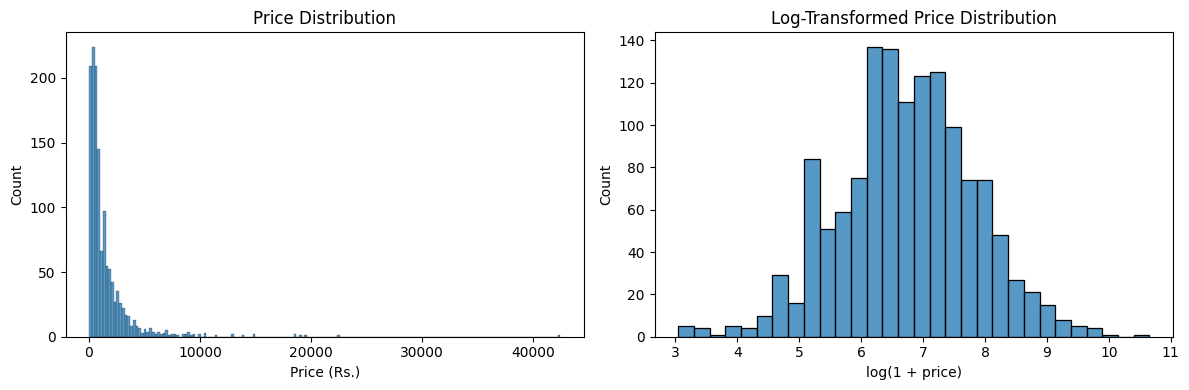

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="price_lkr", ax=axes[0])
sns.histplot(data=df, x="log_price", ax=axes[1])
axes[0].set_title("Price Distribution")
axes[1].set_title("Log-Transformed Price Distribution")

axes[0].set_xlabel("Price (Rs.)")
axes[1].set_xlabel("log(1 + price)")

plt.tight_layout()
plt.show()

price_lkr: The prices of many products are cheap under Rs. 2000 but some products are expensive for example, prisma colour 72 set is Rs. 42,500. Therefore, the left side chart is right skewed. And for variable products the cheapest option is considered to reduce complexity.  
log_price: Used log transformation log(1 + price) to have balanced distribution. Thus, the right side chart is roughly bell shaped.

In [8]:
df.nlargest(10, "price_lkr")[["name", "site", "category_group", "price_lkr"]]

,name,site,category_group,price_lkr
1213,Prismacolor Premier Colour 72 set,jencilstore.com,"Pencils, Charcoal & Pastels",42500.0
1214,Prismacolor Premier 24 Set,jencilstore.com,"Pencils, Charcoal & Pastels",22500.0
123,Uni-posca 16 pen set -(PC-5M),haanz.lk,Pens & Markers,19500.0
124,Uni-posca 16 pen set -(PC-3M),haanz.lk,Pens & Markers,19000.0
125,Uni-posca 16 pen set -(PC-1M),haanz.lk,Pens & Markers,18500.0
1104,Graphic Marker Set – 48 Colors,shanscraftsstore.com,Pens & Markers,18500.0
404,Uni-posca 12 pen set -(PC-1M),haanz.lk,Pens & Markers,14900.0
1257,Watercolour Pad Art Creation A3,jencilstore.com,Paper & Canvas,14900.0
764,Acrylic color paint set Mont Marte 24,shanscraftsstore.com,Acrylic Paint,13800.0
1240,Staedtler Graphite Pencil 24pcs Set,jencilstore.com,"Pencils, Charcoal & Pastels",12960.0


Here, it shows the most expensive products as Prismacolor Premier Colour 72 set and Uni-posca 16 pen sets.

In [9]:
df.nsmallest(10, "price_lkr")[["name", "site", "category_group", "price_lkr"]]

,name,site,category_group,price_lkr
1136,Sketch Papers A4 | A3 | A2,shanscraftsstore.com,Paper & Canvas,20.0
305,Drawing Paper – 100gsm B4,haanz.lk,Paper & Canvas,25.0
306,Drawing Paper – 100gsm A3,haanz.lk,Paper & Canvas,25.0
307,Drawing Paper – 80gsm A3,haanz.lk,Paper & Canvas,25.0
1069,Watercolor Papers A4 | A3 | A2,shanscraftsstore.com,Paper & Canvas,25.0
309,Ivory Paper – 240Gsm A4,haanz.lk,Paper & Canvas,30.0
312,Conqueror Paper Off White -A5 260gsm,haanz.lk,Paper & Canvas,30.0
313,Conqueror Paper White -A5 260gsm,haanz.lk,Paper & Canvas,30.0
777,Transfer Paper A4,shanscraftsstore.com,Paper & Canvas,30.0
919,Sharpener – Faber Castle,shanscraftsstore.com,Tools & Accessories,40.0


The cheapest products are single sheets of drawing paper which ranges from 20 to 25 from Paper & Canvas group. Their prices can be changed with the size A3 or A4 and here it shows the cheapest option.

### 4. Price by category

In [10]:
df["category_group"].value_counts()

category_group
Pencils, Charcoal & Pastels    210
Tools & Accessories            169
Paper & Canvas                 154
Acrylic Paint                  149
Brushes                        144
Pens & Markers                 113
Fabric & Glass Paint           107
Oil Paint                       71
Mediums & Varnishes             53
Poster & Tempera Paint          53
Other Art Supplies              52
Watercolour & Gouache           48
Clay & Sculpting                29
Name: count, dtype: int64

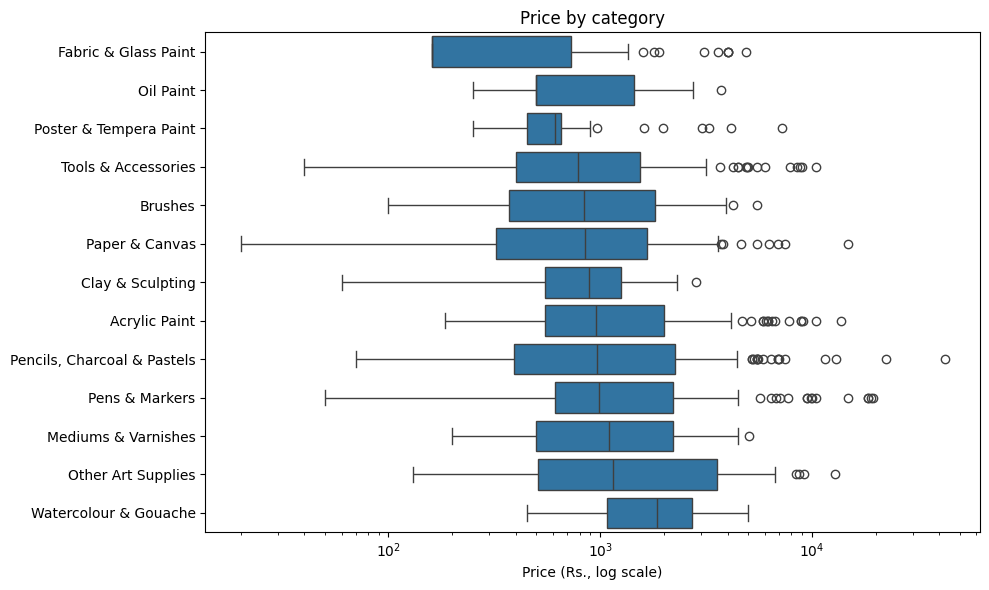

In [11]:
order = df.groupby("category_group")["price_lkr"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="price_lkr", y="category_group", order=order, ax=ax)
ax.set_xscale("log")
ax.set_title("Price by category")
ax.set_xlabel("Price (Rs., log scale)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Fabric & Glass Paint, Oil paint and Poster & Tempera Paint are cheap product categories and Watercolour & Gouache is the expensive product category. 

### 5. Price by brand

In [12]:
df["brand_grouped"].value_counts()

brand_grouped
Unknown            418
Mont Marte         158
Other brand         97
Art Rangers         76
Camlin (Camel)      73
Pentel              73
Marie's             63
Bomeijia            57
Fevicryl            43
Art Nation          37
Sakura              32
Macron              29
Apple (brushes)     29
Faber-Castell       23
Staedtler           21
Fabriano            20
Nyoni               20
Uni                 18
Flash               13
DOMS                11
Crimto              11
Keep Smiling        10
Fujin               10
Tombow              10
Name: count, dtype: int64

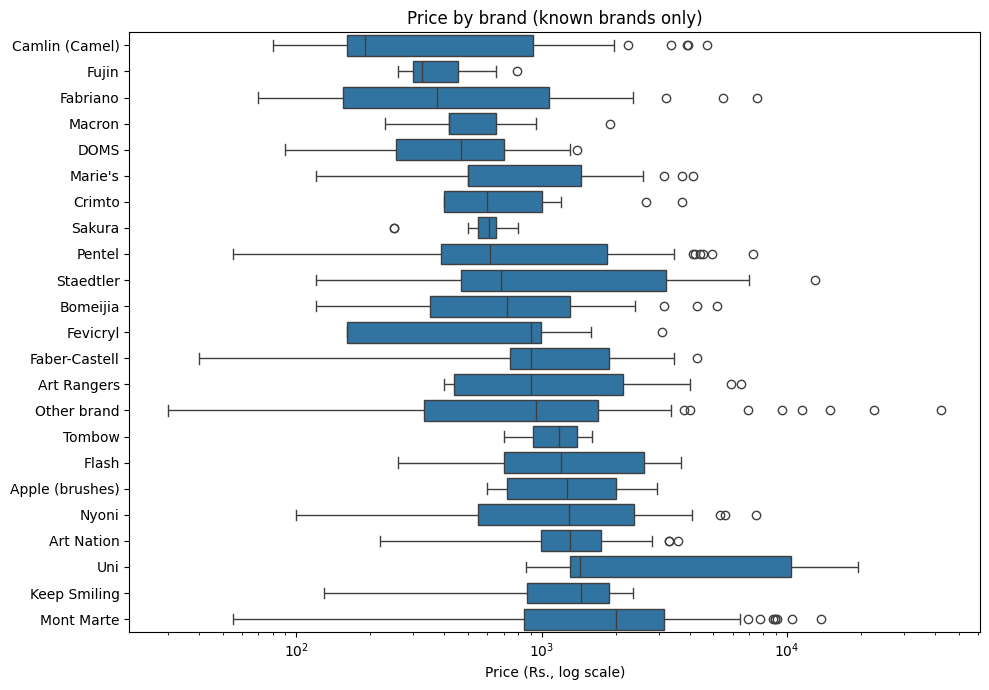

In [13]:
brands = df[df["brand_grouped"] != "Unknown"]
order = brands.groupby("brand_grouped")["price_lkr"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=brands, x="price_lkr", y="brand_grouped", order=order, ax=ax)
ax.set_xscale("log")
ax.set_title("Price by brand (known brands only)")
ax.set_xlabel("Price (Rs., log scale)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Camlin and Fujin are the cheapest brands while Mont Marte, Keep Smiling and Uni are the expensive brands.  
There is also a limitation of unknown brands of 418 products.

### 6. Price by shop

In [14]:
df.groupby("site")["price_lkr"].agg(["count", "median", "mean"]).round(0)

,count,median,mean
site,,,
haanz.lk,683,740.0,1387.0
jencilstore.com,153,1350.0,2342.0
shanscraftsstore.com,516,850.0,1493.0


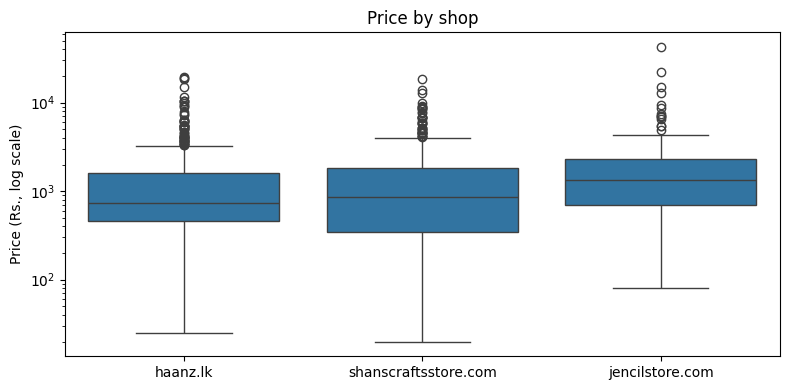

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="site", y="price_lkr", ax=ax)
ax.set_yscale("log")
ax.set_title("Price by shop")
ax.set_ylabel("Price (Rs., log scale)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [16]:
brand_shop = (df[df["brand_grouped"] != "Unknown"]
              .pivot_table(index="brand_grouped", columns="site",
                           values="price_lkr", aggfunc="median")
              .dropna(thresh=2))
brand_shop.round(0)

site,haanz.lk,jencilstore.com,shanscraftsstore.com
brand_grouped,,,
Art Nation,1300.0,1200.0,2250.0
Art Rangers,400.0,1375.0,750.0
Bomeijia,620.0,810.0,1275.0
Camlin (Camel),450.0,415.0,160.0
Faber-Castell,740.0,2600.0,1135.0
Fabriano,305.0,6500.0,NaN
Fevicryl,990.0,NaN,160.0
Keep Smiling,790.0,1950.0,1150.0
Marie's,500.0,1050.0,120.0


The medians of the shops are Haanz Rs.740, Shans Rs.850 and Jencil Rs.1350. Also from brand x shop table we can see that the same brand costs differently in different shops. For example, Art Nation is Rs.1300 at Haanz but it is Rs.2250 at Shans.

### 7. Size and quantity features

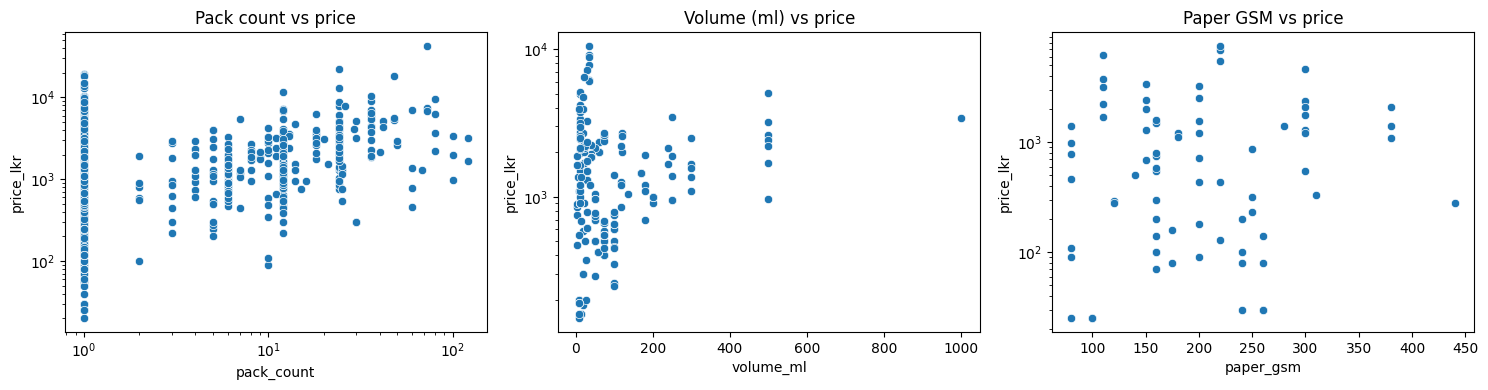

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x="pack_count", y="price_lkr", ax=axes[0])
sns.scatterplot(data=df, x="volume_ml", y="price_lkr", ax=axes[1])
sns.scatterplot(data=df, x="paper_gsm", y="price_lkr", ax=axes[2])
for a in axes:
    a.set_yscale("log")
axes[0].set_xscale("log")
axes[0].set_title("Pack count vs price")
axes[1].set_title("Volume (ml) vs price")
axes[2].set_title("Paper GSM vs price")
plt.tight_layout()
plt.show()

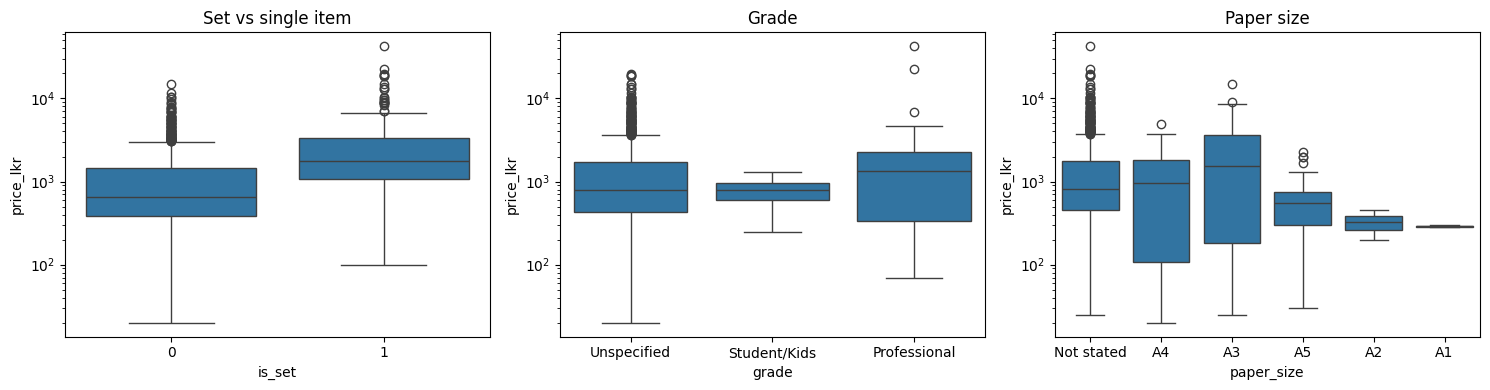

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="is_set", y="price_lkr", ax=axes[0])
sns.boxplot(data=df, x="grade", y="price_lkr", ax=axes[1])
sns.boxplot(data=df, x="paper_size", y="price_lkr", ax=axes[2])
for a in axes:
    a.set_yscale("log")
axes[0].set_title("Set vs single item")
axes[1].set_title("Grade")
axes[2].set_title("Paper size")
plt.tight_layout()
plt.show()

According to above plots we can see that sets cost more than single items and the professional items also show higher prices. And bigger packs and volumes have higher prices.

### 8. Other features

In [19]:
for col in ["on_sale", "in_stock", "is_variable", "n_variants"]:
    print(df[col].value_counts(), "\n")

on_sale
0    1310
1      42
Name: count, dtype: int64 

in_stock
1    1326
0      26
Name: count, dtype: int64 

is_variable
0    1245
1     107
Name: count, dtype: int64 

n_variants
1     1250
2       26
3       20
4        9
6        7
10       6
8        5
13       4
5        4
11       3
14       3
19       3
20       2
9        2
12       2
18       1
17       1
27       1
23       1
7        1
25       1
Name: count, dtype: int64 



Here, only 42 products are on sale, 26 are out of stock and 107 are variable. (These will have a less impact)

### 9. Correlation

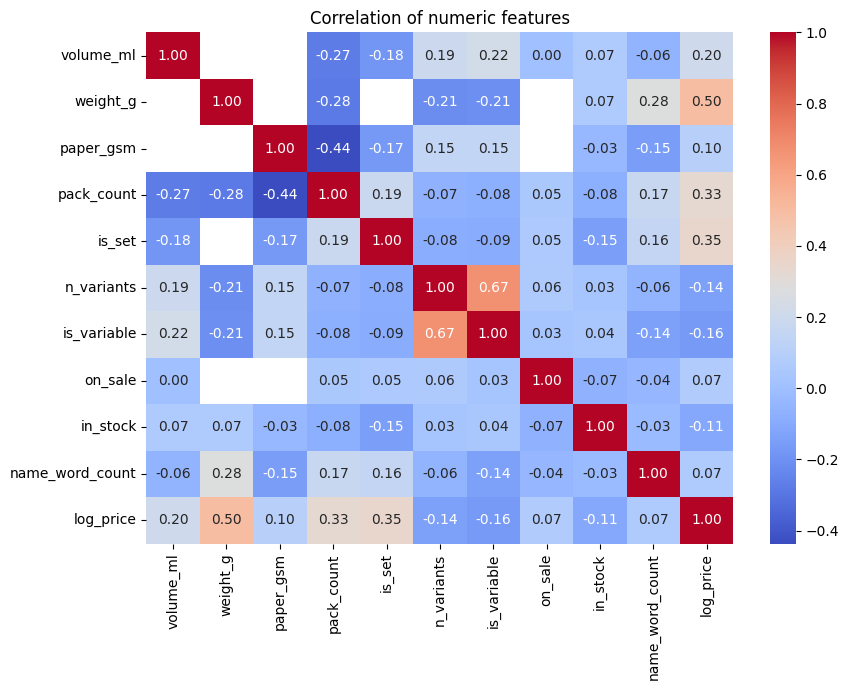

In [20]:
num = df.select_dtypes("number").drop(columns=["product_id", "price_lkr"])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation of numeric features")
plt.tight_layout()
plt.show()

The features most related to log price are is_set (0.35) and pack_count (0.33), so sets and bigger packs have higher price. Weight_g shows 0.5 but it has only 18 products. is_variable shows -0.16 (negative) as variable products are recorded at their cheapest option.

### 10. Summary

**Findings**:  
Prices are right skewed, so log prices are used as the target.  
Category: Fabric & Glass, Oil and Poster paints are cheapest while Watercolour & Gouache is the most expensive.  
Brand: Camlin and Fujin are cheapest and Mont Marte, Keep Smiling and Uni are most expensive.  
Shop: Jencil has the highest median price (Rs.1350) and the same brand can have different prices at different shops.  
Sets, bigger packs and professional items show higher prices.

**Decisions**:  
Target: log_price  
Features: category_group, brand_grouped, grade, paper_size, site, volume_ml, weight_g, paper_gsm, pack_count, is_set, n_variants, is_variable, on_sale, in_stock, name_word_count (identifiers are not used)  
Missing size values: filled with 0 (volume_ml, weight_g, paper_gsm)

**Limitations**:  
One snapshot in time and consider only 3 shops (3 other shops were excluded. Two do not allow their data to be used for AI training and one blocked automated access)  
Unknown brand for 418 products  
Price can depend on other features that are not listed, so predictions will not be perfect.